<a href="https://colab.research.google.com/github/CookOLo/MAT422/blob/main/HW_3_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3.4 - Logistic Regression

- **logistical regression**: a model that in its basic form uses a logistic function to model a binary dependent variable

input data ($\{(\alpha_i, b_i): i = 1,...,n\}$):
- features: $\alpha_i ∈ R^d$
- label: $b_i ∈ \{0,1\}$

**Goal**: find a function of the features that approximates the probability of the label 1

**Logit Formula**:
$$\log \frac{p(\alpha; x)}{1 - p(\alpha; x)} = \alpha^T x$$
aka
$${p(\alpha; x)} = σ(\alpha^T x)$$

where ${p(\alpha; x)} =$ probability that output is 1

**Likelihood (assuming independence given features)**:

$$L(x;A,b)=∏_{i=1}^n p(α_i;x)^{bi}(1−p(αi;x))^{1−b_i}$$

**Cross-entropy loss (negative log-likelihood, normalized by $- \frac{1}{n}$)**:

$$ℓ(x;A,b)=−\frac{1}{n}∑_{i=1}^n b_i \log ⁡(σ(α_i^T x))− \frac{1}{n} ∑_{i=1}^n (1−b_i) \log ⁡(1−σ(α_i^Tx))$$

**Optimization problem**:
$$min⁡_{x∈R^d} ℓ(x;A,b)$$


**Sigmoid derivative**:
$$σ′(t)=σ(t)(1−σ(t))$$


**Gradient of sigmoid**:
$$∇x^σ(α^Tx)=σ(α^Tx)(1−σ(α^Tx))α$$

**Gradient of loss function**:
$$∇x^ℓ(x;A,b) = −\frac{1}{n} ∑_{i=1}^n (b_i−σ(α_i^Tx))α_i$$


- The gradient is simply the prediction error times the feature vector

**Hessian**:
$$∇_x^2 ℓ(x;A,b) = \frac{1}{n} ∑_{i=1}^n σ(α_i^T x) (1−σ(α_i^Tx))α_i α_i^T$$

- Each term $α_i α^T_i$ is symmetric and positive semi-definite (PSD)
  
**Standard gradient descent (step size $β$)**:
$$x_{k+1} = x_k + β \frac{1}{n} ∑_{i=1}{n} (b_i − σ(α_i^T x_k))α_i$$


**Stochastic gradient descent (SGD) (pick random sample I)**:
$$x_{k+1} = x_{k} +β(b_I − σ(α_I^T x_k))α_I$$

- SGD updates using a single random sample, making it faster for large datasets.

In [59]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy.optimize
import seaborn as sns
from sklearn.linear_model import LogisticRegression


Text(0.5, 1.0, 'Features 6 vs 7')

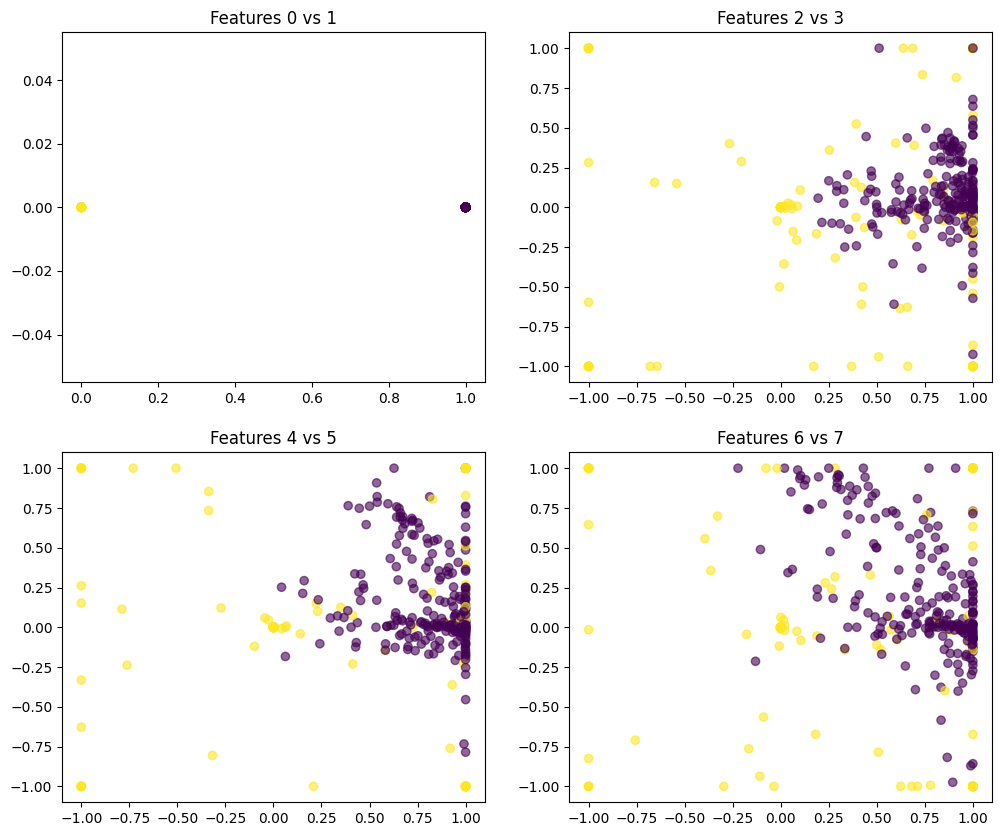

In [29]:
# Example dataset
data= pd.read_csv('https://archive.ics.uci.edu/ml/machine-learning-databases/ionosphere/ionosphere.data', header=None)

X = data.iloc[:, :-1]
y = data.iloc[:, -1]

# CSubplots showing different feature pairs
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
color_map = y.map({'g': 0, 'b': 1})






# Different feature combinations (sample because the dataset is so large)
axes[0, 0].scatter(X.iloc[:, 0], X.iloc[:, 1], c=color_map, cmap='viridis', alpha=0.6)
axes[0, 0].set_title('Features 0 vs 1')

axes[0, 1].scatter(X.iloc[:, 2], X.iloc[:, 3], c=color_map, cmap='viridis', alpha=0.6)
axes[0, 1].set_title('Features 2 vs 3')

axes[1, 0].scatter(X.iloc[:, 4], X.iloc[:, 5], c=color_map, cmap='viridis', alpha=0.6)
axes[1, 0].set_title('Features 4 vs 5')

axes[1, 1].scatter(X.iloc[:, 6], X.iloc[:, 7], c=color_map, cmap='viridis', alpha=0.6)
axes[1, 1].set_title('Features 6 vs 7')

In [74]:
# Convert x and y to numeric values -- y is a converted to binary where g = 1 and b = 0
X = data.iloc[:, :-1].values.astype(float)
y = (data.iloc[:, -1].values == "g").astype(float)

# sigmoid function
def sigmoid(x) :
  return 1 / (1 + np.exp(-x))

def net_input(theta, x):
  return np.dot(x, theta)

# probability of the output to be 1
def probability(theta, x):
  return sigmoid(net_input(theta, x))

# cost function
def cost_function(theta, x, y):
  m = x.shape[0]
  total_cost = -(1 / m) * np.sum(y * np.log(probability(theta, x)) + (1 - y) * np.log(1 - probability(theta, x)))
  return total_cost

# gradient
def gradient(theta, x, y):
  m = x.shape[0]
  return (1 / m) * np.dot(x.T, sigmoid(net_input(theta, x)) - y)

def fit(x, y, theta):
  opt_weights = scipy.optimize.fmin_tnc(func = cost_function, x0 = theta, fprime = gradient, args = (x, y.flatten()))
  return opt_weights[0]

X = np.c_[np.ones((X.shape[0], 1)), X]
y = y[:, np.newaxis]
theta = np.zeros((X.shape[1]))
parameters = fit(X, y, theta)

x_values = np.linspace(X[:, 7].min() - 0.5, X[:, 7].max() + 0.5, 100)
y_values = -(parameters[0] + parameters[7] * x_values) / parameters[8]



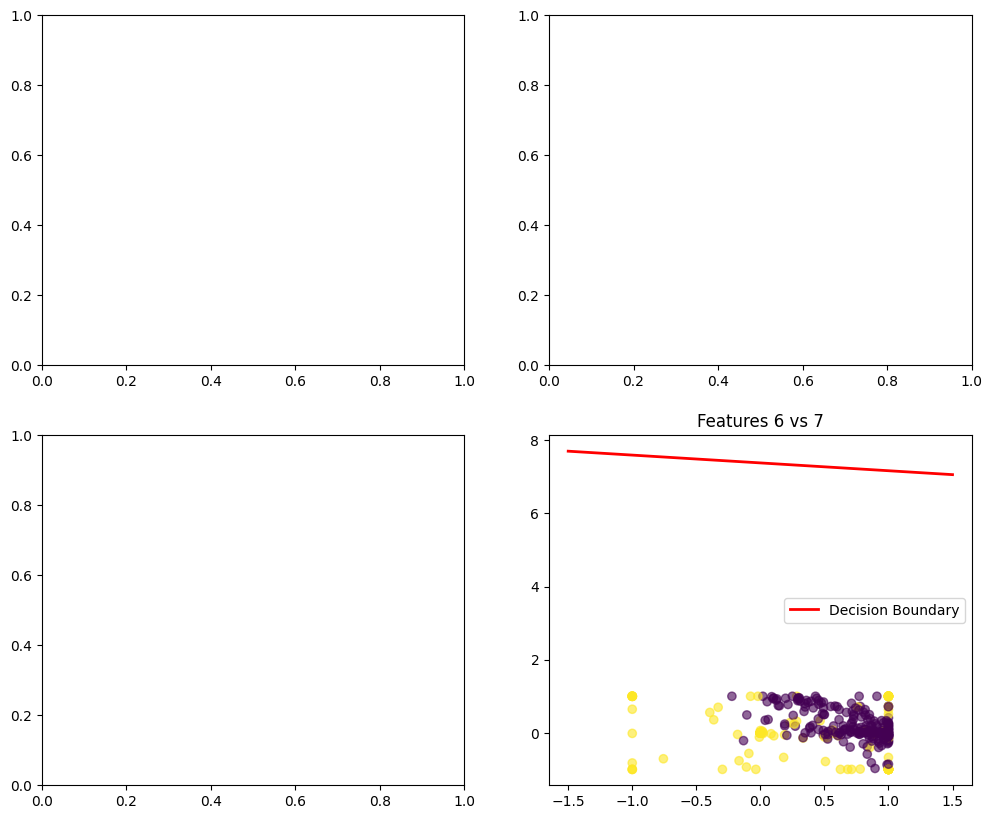

In [76]:
# Plotting with ^ as a Decision Boundary -- only for features 6 vs 7 (where logisitic regression model is exactly undecided between two classes)




X = data.iloc[:, :-1]
y = data.iloc[:, -1]

# Subplots showing different feature pairs
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
color_map = y.map({'g': 0, 'b': 1})






# Different feature combinations (sample because the dataset is so large)
axes[1, 1].scatter(X.iloc[:, 6], X.iloc[:, 7], c=color_map, cmap='viridis', alpha=0.6)
axes[1, 1].set_title('Features 6 vs 7')
axes[1, 1].plot(x_values, y_values, 'r-', linewidth=2, label='Decision Boundary')
axes[1, 1].legend()


In [94]:
# How well the logist regression model performs


def predict(x):
  theta = parameters[:, np.newaxis]
  return probability(theta, x)

def accuracy(x, actual_classes, threshold = 0.5):
  predicted_classes = (predict(x) >= threshold).astype(int)
  predicted_classes = predicted_classes.flatten()
  accuracy = np.mean(predicted_classes == actual_classes)
  return accuracy * 100


X_with_bias = np.c_[np.ones((X.shape[0], 1)), X]  ## Adding the Bias Column Back
y = (data.iloc[:, -1].values == "g").astype(float)
print("Logistic Regression Model performed with a accuracy of percentage: ", accuracy(X_with_bias, y.flatten()))


Logistic Regression Model performed with a accuracy of percentage:  93.73219373219374
